<a href="https://colab.research.google.com/github/kjmobile/lb2/blob/main/5_Naive_Bayes_No_Shows_and_Late_Flights_all.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 5. Naive Bayes: No-Shows and Late Flights

Airlines overbook because some passengers never come. To decide how far to overbook, an airline needs a
**probability** for each booking: how likely is a no-show, given what we know about it?

**Naive Bayes** answers this by counting past cases. It is fast, easy to explain, and was behind early spam filters.

- **Predict (y):** `no_show` (1 = the passenger did not come) in Part 1; `late` (1 = arrived 15 or more minutes late, 0 = on time) in Part 2
- **From (X):** `refundable` and `early` in Part 1; `plane_late`, `short_turn` and `evening` in Part 2

Slides: W3.1, Naive Bayes.

- **Part 1** uses 20 made-up bookings, the same ones as on the slides, so you can check every number by hand.
- **Part 2** uses 2,000 real flights from 2024 to predict which flights arrive late.

> **Full version.** This notebook includes the code that draws every figure. The `_simple` version leaves that code out and shows the same figures as pictures.

### Key formulas

NS = no-show, SH = showed up, R = refundable fare, E = booked 60+ days out ("early").

**Bayes' theorem**

$$P(\mathrm{NS}\mid R)=\frac{P(R\mid \mathrm{NS})\,P(\mathrm{NS})}{P(R)}$$

- $P(\mathrm{NS})$: how common no-shows are before we look at the booking (the **base rate**)
- $P(R\mid \mathrm{NS})$: how often a no-show holds a refundable fare (read "$\mid$" as "given")
- $P(\mathrm{NS}\mid R)$: what we want, the chance of a no-show **given** a refundable fare

**Naive Bayes with two clues: multiply one rate per clue, then compare**

$$\text{score}_{\mathrm{NS}}=P(\mathrm{NS})\,P(R\mid \mathrm{NS})\,P(E\mid \mathrm{NS}),\qquad
P(\mathrm{NS}\mid R,E)=\frac{\text{score}_{\mathrm{NS}}}{\text{score}_{\mathrm{NS}}+\text{score}_{\mathrm{SH}}}$$

---
# Part 1. Twenty Bookings

> **Data.** 20 made-up bookings for teaching, not real airline statistics. Each row is one booking:
> `no_show` (1 = did not come), `refundable` (1 = refundable fare), `early` (1 = booked 60+ days out),
> `bag` (1 = checked a bag).

## 1. Count before you calculate

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.naive_bayes import BernoulliNB

bookings = pd.read_csv('https://raw.githubusercontent.com/kjmobile/lb2/main/data/noshow_20.csv')
bookings

,no_show,refundable,early,bag
0,1,1,1,0
1,1,1,1,0
2,1,1,0,0
3,1,1,0,0
4,1,0,1,0
5,0,1,1,1
6,0,1,0,1
7,0,1,0,1
8,0,0,1,1
9,0,0,1,1


In [2]:
bookings['no_show'].value_counts()

no_show
0    15
1     5
Name: count, dtype: int64

In [3]:
# how many bookings in each group carry each clue (0 = showed up, 1 = no-show)
bookings.groupby('no_show')[['refundable', 'early', 'bag']].sum()

,refundable,early,bag
no_show,,,
0,3,4,6
1,4,3,0


Three numbers to keep: $P(\mathrm{NS})$ = 5 of 20 = 25%, $P(R\mid \mathrm{NS})$ = 4 of 5 = 80%,
$P(R\mid \mathrm{SH})$ = 3 of 15 = 20%.

## 2. One clue: count it, or use Bayes' theorem

A new booking has a refundable fare. First, count inside the clue:

In [4]:
refundable = bookings[bookings['refundable'] == 1]
print('no-shows among refundable bookings:', refundable['no_show'].sum(), 'of', len(refundable))
print('P(no-show | R) =', round(refundable['no_show'].mean(), 3))

no-shows among refundable bookings: 4 of 7
P(no-show | R) = 0.571


Bayes' theorem with the counts above gives the same answer: $\dfrac{4/5 \times 5/20}{7/20}$

In [5]:
print(round((4/5 * 5/20) / (7/20), 3))

0.571


## 3. The base rate: same clue, different answer

Keep the clue exactly as strong (80% of no-shows hold a refundable fare, 20% of passengers who fly do).
Change only how common no-shows are on the route.

In [6]:
def after_clue(base_rate):
    # P(no-show | R) when P(R | no-show) = 0.8 and P(R | showed up) = 0.2
    return 0.8 * base_rate / (0.8 * base_rate + 0.2 * (1 - base_rate))

print('route with 25% no-shows:', round(after_clue(0.25), 2))
print('route with  5% no-shows:', round(after_clue(0.05), 2))

route with 25% no-shows: 0.57
route with  5% no-shows: 0.17


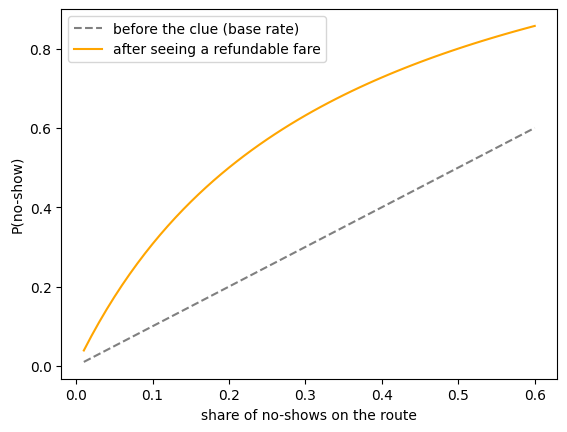

In [7]:
# Figure 1
base = np.linspace(0.01, 0.6, 60)
plt.plot(base, base, '--', color='gray', label='before the clue (base rate)')
plt.plot(base, after_clue(base), color='orange', label='after seeing a refundable fare')
plt.xlabel('share of no-shows on the route')
plt.ylabel('P(no-show)')
plt.legend()
plt.show()

The same clue moves a 25% route to 57%, but a 5% route only to 17%. A rare event stays fairly unlikely even after a
good clue. Ignoring the base rate is one of the most common mistakes in reading evidence.

## 4. Two clues and the "naive" assumption

The booking is refundable **and** booked 60+ days out. Naive Bayes multiplies one rate per clue, as if the two clues
were **independent** (knowing one tells you nothing about the other). That shortcut is what "naive" means.

In [8]:
score_ns = 5/20 * 4/5 * 3/5          # P(NS) x P(R | NS) x P(E | NS)
score_sh = 15/20 * 3/15 * 4/15       # P(SH) x P(R | SH) x P(E | SH)

print('score no-show:  ', round(score_ns, 2))
print('score showed up:', round(score_sh, 2))
print('Naive Bayes P(no-show | R, E) =', round(score_ns / (score_ns + score_sh), 2))

score no-show:   0.12
score showed up: 0.04
Naive Bayes P(no-show | R, E) = 0.75


Now count the bookings that really have both clues:

In [9]:
both = bookings[(bookings['refundable'] == 1) & (bookings['early'] == 1)]
print('no-shows among bookings with both clues:', both['no_show'].sum(), 'of', len(both))
print('counted P(no-show | R, E) =', round(both['no_show'].mean(), 2))

no-shows among bookings with both clues: 2 of 3
counted P(no-show | R, E) = 0.67


75% against 67%: the gap is the price of treating the two clues as independent. Why pay it? With 10 yes/no clues
there are 1,024 combinations, and most of them never appear in the data, so counting stops working. Naive Bayes needs
only one rate per clue.

scikit-learn's `BernoulliNB` (Naive Bayes for yes/no clues) does the same arithmetic. `alpha` is the smoothing
explained in section 5; we set it almost to 0 here so the answer matches the hand calculation.

In [10]:
nb_20 = BernoulliNB(alpha=0.000001)
nb_20.fit(bookings[['refundable', 'early']], bookings['no_show'])

new_booking = pd.DataFrame({'refundable': [1], 'early': [1]})
print(nb_20.predict_proba(new_booking)[:, 1].round(2))

[0.75]


`predict_proba` gives two columns: the probability of class 0 (showed up) and of class 1 (no-show). `[:, 1]` keeps
the second.

## 5. A zero count, and the fix

None of the 5 no-shows checked a bag. One zero makes the whole product in the score equal 0, whatever the other
clues say. **Laplace smoothing** adds 1 to every count (and 2 to the total, one for each answer, yes or no):

In [11]:
print('P(bag | no-show) =', bookings[bookings['no_show'] == 1]['bag'].mean())
print('with Laplace smoothing: (0 + 1) / (5 + 2) =', round((0 + 1) / (5 + 2), 3))

P(bag | no-show) = 0.0
with Laplace smoothing: (0 + 1) / (5 + 2) = 0.143


`BernoulliNB()` uses this smoothing by default (`alpha=1`).

---
# Part 2. Which Flights Will Arrive Late?

Now real data, and a question an airline's operations center asks every day.

> **Data.** 2,000 U.S. domestic flights from 2024, picked at random from the on-time records of the U.S. Bureau of
> Transportation Statistics (BTS), read straight from the course GitHub repository. Source: BTS Marketing Carrier
> On-Time Performance, 2024 (public data).

| Column | Meaning |
|---|---|
| `month` | 1 = January ... 12 = December |
| `dep_hour` | scheduled departure hour (6 = 6 a.m., 18 = 6 p.m.) |
| `distance` | flight distance in miles |
| `inbound_delay` | how late the **incoming plane** arrived, in minutes (negative = early). An airplane flies several legs a day, so the plane for this flight usually flies in from another airport first |
| `turn_minutes` | scheduled minutes between the incoming plane's arrival and this flight's departure |
| `late` | 1 = arrived 15 or more minutes late (the official definition of a late flight), 0 = on time |

In [12]:
flights = pd.read_csv('https://raw.githubusercontent.com/kjmobile/lb2/main/data/flights_late_2024.csv')
flights.head()

,month,dep_hour,distance,inbound_delay,turn_minutes,late
0,7,17,195,4,35,0
1,1,14,239,1,50,0
2,4,18,986,-7,84,0
3,4,8,224,5,30,0
4,8,16,327,36,45,1


In [13]:
print(flights.shape)
print('share of late flights:', round(flights['late'].mean(), 3))

(2000, 6)
share of late flights: 0.208


## 6. Turn the numbers into yes/no clues

`BernoulliNB` works with yes/no clues, like the bookings in Part 1. We make three:

In [14]:
clues = pd.DataFrame({
    'plane_late': (flights['inbound_delay'] >= 15).astype(int),   # incoming plane 15+ minutes late
    'short_turn': (flights['turn_minutes'] < 45).astype(int),     # less than 45 minutes to turn the plane around
    'evening':    (flights['dep_hour'] >= 17).astype(int),        # leaves at 5 p.m. or later
    'late':       flights['late']})
clues.head()

,plane_late,short_turn,evening,late
0,0,1,1,0
1,0,0,0,0
2,0,0,1,0
3,0,1,0,0
4,1,0,0,1


In [15]:
# share of flights carrying each clue: on-time flights (0) vs late flights (1). These are P(clue | late).
clues.groupby('late')[['plane_late', 'short_turn', 'evening']].mean().round(3)

,plane_late,short_turn,evening
late,,,
0,0.076,0.225,0.330
1,0.542,0.277,0.434


In [16]:
# the other direction: share of late flights when the clue is absent (0) or present (1)
rates = pd.DataFrame({clue: clues.groupby(clue)['late'].mean() for clue in ['plane_late', 'short_turn', 'evening']}).T
rates.columns = ['clue absent', 'clue present']
rates.round(3)

,clue absent,clue present
plane_late,0.115,0.650
short_turn,0.196,0.244
evening,0.181,0.256


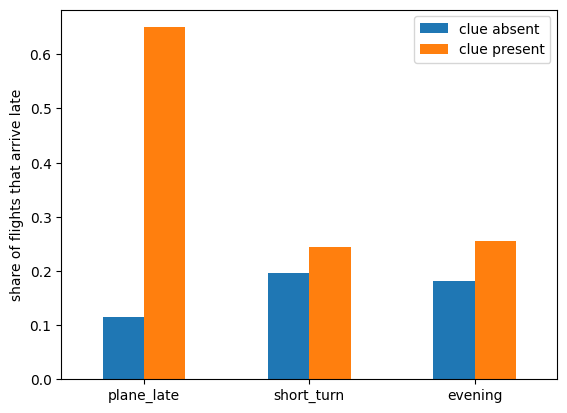

In [17]:
# Figure 2
rates.plot(kind='bar', rot=0)
plt.ylabel('share of flights that arrive late')
plt.show()

A late incoming plane is by far the strongest clue: most flights whose plane comes in late also arrive late.
A short turn and an evening departure each add a little.

## 7. Train and test

As in notebook 4, we keep 20% of the flights aside as a **test set**.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix

X = clues[['plane_late', 'short_turn', 'evening']]
y = clues['late']
train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.2, random_state=320, stratify=y)

nb = BernoulliNB()
nb.fit(train_X, train_y)

print('test accuracy:', round(nb.score(test_X, test_y), 3))
print('baseline (always guess "on time"):', round(1 - test_y.mean(), 3))

test accuracy: 0.858
baseline (always guess "on time"): 0.792


In [19]:
# rows: what really happened (0 on time, 1 late); columns: what the model said
confusion_matrix(test_y, nb.predict(test_X))

array([[298,  19],
       [ 38,  45]], dtype=int64)

## 8. Naive vs. counted, on real data

Take a flight whose incoming plane is late **and** whose turn is short (morning departure). Compare the Naive Bayes
answer with simply counting such flights.

In [20]:
flight = pd.DataFrame({'plane_late': [1], 'short_turn': [1], 'evening': [0]})
print('Naive Bayes P(late):', round(nb.predict_proba(flight)[0, 1], 3))

same = clues[(clues['plane_late'] == 1) & (clues['short_turn'] == 1) & (clues['evening'] == 0)]
print('counted P(late):', round(same['late'].mean(), 3), 'among', len(same), 'such flights')

Naive Bayes P(late): 0.654
counted P(late): 0.875 among 40 such flights


The two answers are far apart, much more than in Part 1. The clues are **not** independent: a short turn hardly
matters when the plane arrives on time, but it leaves no room to recover when the plane is late. Naive Bayes
multiplies the clues one by one, so it cannot see that they work together. This is the cost of the naive shortcut;
the decision tree in notebook 6 can see such combinations.

### Your turn

A flight leaves in the **evening** with a **short turn**, but its incoming plane is **on time**.

1. In the cell below, fill in the blanks (`___`) and run it.
2. Then finish this sentence:
   *Naive Bayes gives this flight a ___ chance of arriving late; counting such flights gives ___.*

<details><summary>Show answer</summary>

```python
flight_2 = pd.DataFrame({'plane_late': [0], 'short_turn': [1], 'evening': [1]})
print('Naive Bayes P(late):', round(nb.predict_proba(flight_2)[0, 1], 3))

same_2 = clues[(clues['plane_late'] == 0) & (clues['short_turn'] == 1) & (clues['evening'] == 1)]
print('counted P(late):', round(same_2['late'].mean(), 3), 'among', len(same_2), 'such flights')
```

*Naive Bayes gives this flight a **0.164** chance of arriving late; counting such flights gives **0.132**. With the plane on time, the two answers are close.*
</details>

In [ ]:
flight_2 = pd.DataFrame({'plane_late': [___], 'short_turn': [1], 'evening': [1]})
print('Naive Bayes P(late):', round(nb.___(flight_2)[0, 1], 3))

same_2 = clues[(clues['plane_late'] == 0) & (clues['short_turn'] == 1) & (clues['evening'] == 1)]
print('counted P(late):', round(same_2['late'].mean(), 3), 'among', len(same_2), 'such flights')

## 9. Summary

| Step | What we found |
|---|---|
| Bayes' theorem | P(no-show given a refundable fare) = 4/7 = 57%, by counting or by the formula |
| Base rate | The same clue gives 57% on a 25% route but only 17% on a 5% route |
| Naive shortcut | Multiply one rate per clue: 75% against 67% counted in the 20 bookings |
| Zero counts | Laplace smoothing: (0 + 1) / (5 + 2) instead of 0 |
| Real flights | A late incoming plane is the strongest clue; Naive Bayes beats always guessing "on time" |
| Its limit | Clues that work together (late plane + short turn) are underestimated |

---
# Challenge

1. In section 3, what share of no-shows would a route need for a refundable fare to push P(no-show) above 50%?
   (Hint: try `after_clue(0.15)`, `after_clue(0.2)`, ...)
2. Add a fourth clue to Part 2, for example a long flight (`distance` of 1,500 miles or more). Does the test accuracy
   change? Why or why not?
3. If overbooking by the expected number of no-shows sometimes bumps a passenger, should the airline overbook by
   less? What costs would you compare?

In [22]:
# Your answer